In [1]:
import numpy as np
import pandas as pd
from pathlib import Path

CACHE = Path("cache")
KEYS = ["split", "id"]

# --- load ---
llm = pd.read_csv(CACHE / "llm_results.csv")
s0  = pd.read_csv(CACHE / "s0_preds.csv")

# --- the three gotchas ---
llm["id"]   = llm["id"].astype(int)
s0["id"]    = s0["id"].astype(int)
llm["text"] = llm["text"].fillna("")          # failed outputs have empty text
llm["pred"] = llm["pred"].fillna("INVALID")   # invalid counts as wrong

assert set(llm["model"]) == {"small", "large"}, set(llm["model"])

# --- one row per (split, id), models side by side ---
def side(model):
    d = llm[llm["model"] == model].drop(columns="model")
    return d.rename(columns={c: f"{model}_{c}" for c in d.columns if c not in KEYS})

df = side("small").merge(side("large"), on=KEYS, validate="one_to_one")
assert (df["small_gold"] == df["large_gold"]).all()
df["gold"] = df["small_gold"]
df = df.drop(columns=["small_gold", "large_gold"])
df = df.merge(s0, on=KEYS, how="inner", validate="one_to_one")

# --- sanity checks against Day 2 ---
print("rows per split:\n", df["split"].value_counts(), "\n")
print("columns with NaN:\n", df.isna().sum()[lambda s: s > 0], "\n")

for split, g in df.groupby("split"):
    print(split,
          f"| S0 {(g.s0_pred == g.gold).mean():.3f}",
          f"| small {(g.small_pred == g.gold).mean():.3f}",
          f"| large {(g.large_pred == g.gold).mean():.3f}",
          f"| invalid small/large {(g.small_pred == 'INVALID').sum()}/{(g.large_pred == 'INVALID').sum()}")

rows per split:
 split
validation    150
test          150
Name: count, dtype: int64 

columns with NaN:
 small_confidence    2
dtype: int64 

test | S0 0.800 | small 0.700 | large 0.780 | invalid small/large 1/0
validation | S0 0.787 | small 0.767 | large 0.793 | invalid small/large 1/0


In [2]:
# USD per 1M tokens: (input, output). Published Groq prices; we're on the free tier,
# so this is an ESTIMATE of what the same calls would cost on a paid plan.
PRICES = {"small": (0.075, 0.30), "large": (0.15, 0.60)}

def row_cost(prompt_tokens, completion_tokens, model):
    p_in, p_out = PRICES[model]
    return (prompt_tokens * p_in + completion_tokens * p_out) / 1_000_000

for m in PRICES:
    df[f"{m}_cost"] = row_cost(df[f"{m}_prompt_tokens"], df[f"{m}_completion_tokens"], m)

# check against Day 2 (all 300 rows per model): expect large ~0.0813, small ~0.0418
print((df[["small_cost", "large_cost"]].mean() * 1000).round(4))

small_cost    0.0418
large_cost    0.0813
dtype: float64


In [3]:
from sklearn.metrics import f1_score

def metrics(gold, pred, latency=None, cost=None):
    """One function for every system (S0, A, B, and later C, D).
    gold, pred: label per request ("INVALID" = unusable output, counts as wrong)
    latency:    seconds per request (None if not measured)
    cost:       USD per request     (None if not applicable)
    """
    gold, pred = np.asarray(gold), np.asarray(pred)
    present = sorted(set(gold))                      # classes that appear in THIS sample
    out = {
        "n": len(gold),
        "acc": (gold == pred).mean(),
        "macro_f1": f1_score(gold, pred, labels=present, average="macro", zero_division=0),
        "invalid_rate": (pred == "INVALID").mean(),
        "lat_median": np.nan, "lat_p95": np.nan, "cost_per_1k": np.nan,
    }
    if latency is not None:
        out["lat_median"] = np.median(latency)
        out["lat_p95"] = np.percentile(latency, 95)
    if cost is not None:
        out["cost_per_1k"] = np.mean(cost) * 1000
    return out

def system_table(g):
    return pd.DataFrame({
        "S0":      metrics(g.gold, g.s0_pred),
        "A small": metrics(g.gold, g.small_pred, g.small_latency_s, g.small_cost),
        "B large": metrics(g.gold, g.large_pred, g.large_latency_s, g.large_cost),
    }).T

for split in ["validation", "test"]:
    print(f"=== {split} ===")
    print(system_table(df[df["split"] == split]).round(3), "\n")

=== validation ===
             n    acc  macro_f1  invalid_rate  lat_median  lat_p95  \
S0       150.0  0.787     0.767         0.000         NaN      NaN   
A small  150.0  0.767     0.821         0.007       1.357    2.127   
B large  150.0  0.793     0.803         0.000       1.398    2.571   

         cost_per_1k  
S0               NaN  
A small        0.042  
B large        0.081   

=== test ===
             n   acc  macro_f1  invalid_rate  lat_median  lat_p95  cost_per_1k
S0       150.0  0.80     0.791         0.000         NaN      NaN          NaN
A small  150.0  0.70     0.769         0.007       1.432    2.080        0.042
B large  150.0  0.78     0.829         0.000       1.471    2.308        0.081 



In [4]:
from sklearn.metrics import roc_auc_score

val = df[df["split"] == "validation"].copy()
val["small_ok"] = val.small_pred == val.gold
val["large_ok"] = val.large_pred == val.gold
val["s0_ok"]    = val.s0_pred    == val.gold

# What values does verbalized confidence actually take? (before choosing any bins)
for m in ["small", "large"]:
    print(f"--- {m} verbalized confidence, validation ---")
    print(val[f"{m}_confidence"].value_counts(dropna=False).sort_index().to_string(), "\n")

--- small verbalized confidence, validation ---
small_confidence
0.10     2
0.20     1
0.30     2
0.40     4
0.60     4
0.85     5
0.92    32
0.95     8
0.99    91
NaN      1 

--- large verbalized confidence, validation ---
large_confidence
0.30     1
0.45     2
0.78    10
0.87     1
0.88     2
0.92    19
0.96    34
0.97    59
0.99    22 



In [5]:
def reliability(conf, ok, bins):
    d = pd.DataFrame({"conf": conf, "ok": ok}).dropna()          # NaN confidence = invalid output, handled separately
    d["bin"] = pd.cut(d["conf"], bins=bins, include_lowest=True)
    t = d.groupby("bin", observed=True).agg(n=("ok", "size"),
                                            mean_conf=("conf", "mean"),
                                            accuracy=("ok", "mean"))
    return t.round(3)

def summarize(name, conf, ok, bins):
    d = pd.DataFrame({"conf": conf, "ok": ok}).dropna()
    print(f"=== {name} ===")
    print(f"rows with a confidence: {len(d)} of {len(conf)}")
    print(f"mean confidence | right: {d[d.ok].conf.mean():.3f}   wrong: {d[~d.ok].conf.mean():.3f}")
    print(f"AUROC (does confidence rank right above wrong?): {roc_auc_score(d.ok, d.conf):.3f}")
    print(reliability(conf, ok, bins).to_string(), "\n")

BINS_VERB = [0, 0.5, 0.8, 0.9, 0.95, 0.99, 1.0]   # coarse: only 150 rows
BINS_S0   = [0, 0.3, 0.5, 0.7, 0.9, 1.0]

summarize("small, verbalized", val.small_confidence, val.small_ok, BINS_VERB)
summarize("large, verbalized", val.large_confidence, val.large_ok, BINS_VERB)
summarize("S0 probability",    val.s0_conf,          val.s0_ok,    BINS_S0)

=== small, verbalized ===
rows with a confidence: 149 of 150
mean confidence | right: 0.969   wrong: 0.734
AUROC (does confidence rank right above wrong?): 0.796
                n  mean_conf  accuracy
bin                                   
(-0.001, 0.5]   9      0.289     0.000
(0.5, 0.8]      4      0.600     0.250
(0.8, 0.9]      5      0.850     0.000
(0.9, 0.95]    40      0.926     0.800
(0.95, 0.99]   91      0.990     0.901 

=== large, verbalized ===
rows with a confidence: 150 of 150
mean confidence | right: 0.954   wrong: 0.880
AUROC (does confidence rank right above wrong?): 0.808
                 n  mean_conf  accuracy
bin                                    
(-0.001, 0.5]    3      0.400     0.333
(0.5, 0.8]      10      0.780     0.600
(0.8, 0.9]       3      0.877     0.000
(0.9, 0.95]     19      0.920     0.474
(0.95, 0.99]   115      0.971     0.896 

=== S0 probability ===
rows with a confidence: 150 of 150
mean confidence | right: 0.936   wrong: 0.507
AUROC (does con

In [6]:
def reliability(conf, ok, bins):
    d = pd.DataFrame({"conf": conf, "ok": ok}).dropna()          # NaN confidence = invalid output, handled separately
    d["bin"] = pd.cut(d["conf"], bins=bins, include_lowest=True)
    t = d.groupby("bin", observed=True).agg(n=("ok", "size"),
                                            mean_conf=("conf", "mean"),
                                            accuracy=("ok", "mean"))
    return t.round(3)

def summarize(name, conf, ok, bins):
    d = pd.DataFrame({"conf": conf, "ok": ok}).dropna()
    print(f"=== {name} ===")
    print(f"rows with a confidence: {len(d)} of {len(conf)}")
    print(f"mean confidence | right: {d[d.ok].conf.mean():.3f}   wrong: {d[~d.ok].conf.mean():.3f}")
    print(f"AUROC (does confidence rank right above wrong?): {roc_auc_score(d.ok, d.conf):.3f}")
    print(reliability(conf, ok, bins).to_string(), "\n")

BINS_VERB = [0, 0.5, 0.8, 0.9, 0.95, 0.99, 1.0]   # coarse: only 150 rows
BINS_S0   = [0, 0.3, 0.5, 0.7, 0.9, 1.0]

summarize("small, verbalized", val.small_confidence, val.small_ok, BINS_VERB)
summarize("large, verbalized", val.large_confidence, val.large_ok, BINS_VERB)
summarize("S0 probability",    val.s0_conf,          val.s0_ok,    BINS_S0)

=== small, verbalized ===
rows with a confidence: 149 of 150
mean confidence | right: 0.969   wrong: 0.734
AUROC (does confidence rank right above wrong?): 0.796
                n  mean_conf  accuracy
bin                                   
(-0.001, 0.5]   9      0.289     0.000
(0.5, 0.8]      4      0.600     0.250
(0.8, 0.9]      5      0.850     0.000
(0.9, 0.95]    40      0.926     0.800
(0.95, 0.99]   91      0.990     0.901 

=== large, verbalized ===
rows with a confidence: 150 of 150
mean confidence | right: 0.954   wrong: 0.880
AUROC (does confidence rank right above wrong?): 0.808
                 n  mean_conf  accuracy
bin                                    
(-0.001, 0.5]    3      0.400     0.333
(0.5, 0.8]      10      0.780     0.600
(0.8, 0.9]       3      0.877     0.000
(0.9, 0.95]     19      0.920     0.474
(0.95, 0.99]   115      0.971     0.896 

=== S0 probability ===
rows with a confidence: 150 of 150
mean confidence | right: 0.936   wrong: 0.507
AUROC (does con

In [7]:
target = val.small_ok

signals = {
    "small verbalized conf (invalid -> 0)": val.small_confidence.fillna(0),
    "S0 probability":                       val.s0_conf,
}
for name, s in signals.items():
    print(f"AUROC for 'small is right' | {name:38s} {roc_auc_score(target, s):.3f}")

# disagreement signal: does the small model's answer match S0's?
val["agree"] = val.small_pred == val.s0_pred      # an INVALID output never matches, so it counts as disagree
print("\nsmall model accuracy, split by agreement with S0:")
print(val.groupby("agree").agg(n=("small_ok", "size"), small_acc=("small_ok", "mean")).round(3))

print("\nS0 probability, rows where small is right vs wrong:")
print(val.groupby("small_ok").s0_conf.agg(["count", "mean", "median"]).round(3))

AUROC for 'small is right' | small verbalized conf (invalid -> 0)   0.802
AUROC for 'small is right' | S0 probability                         0.769

small model accuracy, split by agreement with S0:
         n  small_acc
agree                
False   38      0.263
True   112      0.938

S0 probability, rows where small is right vs wrong:
          count   mean  median
small_ok                      
False        35  0.632   0.701
True        115  0.909   0.988


## Operating-point rule (written BEFORE the sweep was run)

**Router C** escalates a request to the large model if ANY of these fires:
1. the small model's output is invalid (always on);
2. its verbalized confidence is below t_v;
3. S0's max probability is below t_s;
4. the small model's label disagrees with S0's (switchable: use_disagree).

**Grid, fixed in advance (60 configs):** t_v in {0, 0.5, 0.7, 0.9, 0.93, 0.96},
t_s in {0, 0.3, 0.5, 0.7, 0.9}, use_disagree in {False, True}.
A threshold of 0 switches that signal off.

**Selection rule:** keep the configs whose estimated validation cost saving versus
B is at least 20%. Among them, choose the highest validation accuracy; ties go to
the lower cost. Freeze that config, then compute test once.

**Why 20%:** a saving under about 20% would not justify the extra complexity and
the extra latency of two sequential calls.

**Caveat:** picking the best of 60 configs on 150 rows is optimistic (winner's
curse). The frozen test run is the honest check.

In [8]:
def route(g, t_v, t_s, use_disagree):
    """True = escalate this request to the large model."""
    invalid  = (g.small_pred == "INVALID").to_numpy()
    low_verb = (g.small_confidence.fillna(0) < t_v).to_numpy()
    low_s0   = (g.s0_conf < t_s).to_numpy()
    esc = invalid | low_verb | low_s0
    if use_disagree:
        esc |= (g.small_pred != g.s0_pred).to_numpy()
    return esc

def system_C(g, esc):
    """Given who escalates, build the router's prediction, latency, cost per request."""
    esc  = np.asarray(esc)
    pred = np.where(esc, g.large_pred, g.small_pred)
    lat  = g.small_latency_s.to_numpy() + esc * g.large_latency_s.to_numpy()   # sequential
    cost = g.small_cost.to_numpy()      + esc * g.large_cost.to_numpy()        # small on all + large on escalated
    return pred, lat, cost

def run_C(g, t_v, t_s, use_disagree):
    esc = route(g, t_v, t_s, use_disagree)
    pred, lat, cost = system_C(g, esc)
    out = metrics(g.gold, pred, lat, cost)       # the SAME metrics function as S0, A, B
    out["esc_rate"] = esc.mean()
    return out

def system_D(g, k, n_seeds=2000, seed=0):
    """Escalate exactly k randomly chosen rows; repeat n_seeds times; return mean/sd of accuracy, mean cost per 1k."""
    rng = np.random.default_rng(seed)
    n = len(g)
    s_ok = (g.small_pred == g.gold).to_numpy()
    l_ok = (g.large_pred == g.gold).to_numpy()
    esc = np.zeros((n_seeds, n), dtype=bool)
    if k > 0:
        idx = rng.random((n_seeds, n)).argsort(axis=1)[:, :k]   # first k of a random permutation, per draw
        np.put_along_axis(esc, idx, True, axis=1)
    acc  = np.where(esc, l_ok, s_ok).mean(axis=1)
    cost = (g.small_cost.to_numpy() + esc * g.large_cost.to_numpy()).mean(axis=1) * 1000
    return acc.mean(), acc.std(), cost.mean()

# ---------- sanity checks (no sweep, no results being chosen) ----------
n = len(val)

# 1) only the invalid row escalates; with disagreement on, the 38 disagree rows
assert route(val, 0, 0, False).sum() == 1
assert route(val, 0, 0, True).sum()  == 38

# 2) nobody escalates == system A
pred, lat, cost = system_C(val, np.zeros(n, bool))
assert (pred == val.small_pred.to_numpy()).all()
assert np.isclose(cost.mean(), val.small_cost.mean())

# 3) everybody escalates == B's answers, but pays for BOTH models
pred, lat, cost = system_C(val, np.ones(n, bool))
assert (pred == val.large_pred.to_numpy()).all()
print(f"escalate-all cost per 1k: {cost.mean()*1000:.4f}  "
      f"(small {val.small_cost.mean()*1000:.4f} + large {val.large_cost.mean()*1000:.4f})")

# 4) D should sit on the straight line between A and B
a, b = val.small_ok.mean(), val.large_ok.mean()
for k in [0, 38, 75, 150]:
    acc, sd, c = system_D(val, k)
    line = a + (k / n) * (b - a)
    assert abs(acc - line) < 0.005, (k, acc, line)
    print(f"k={k:3d} | D acc {acc:.4f} (sd {sd:.3f}) | straight line A->B {line:.4f} | cost/1k {c:.4f}")

escalate-all cost per 1k: 0.1228  (small 0.0415 + large 0.0812)
k=  0 | D acc 0.7667 (sd 0.000) | straight line A->B 0.7667 | cost/1k 0.0415
k= 38 | D acc 0.7734 (sd 0.013) | straight line A->B 0.7734 | cost/1k 0.0621
k= 75 | D acc 0.7801 (sd 0.015) | straight line A->B 0.7800 | cost/1k 0.0822
k=150 | D acc 0.7933 (sd 0.000) | straight line A->B 0.7933 | cost/1k 0.1228


In [10]:
import itertools

T_V = [0, 0.5, 0.7, 0.9, 0.93, 0.96]
T_S = [0, 0.3, 0.5, 0.7, 0.9]
DIS = [False, True]
MIN_SAVING = 0.20                       # from the rule cell

cost_B = val.large_cost.mean() * 1000   # B's cost per 1k on validation

rows = []
for t_v, t_s, dis in itertools.product(T_V, T_S, DIS):
    r = run_C(val, t_v, t_s, dis)
    r.update(t_v=t_v, t_s=t_s, use_disagree=dis)
    r["saving"] = 1 - r["cost_per_1k"] / cost_B
    rows.append(r)
sweep = pd.DataFrame(rows)
assert len(sweep) == 60

# D at the same number of escalated rows as each C config
sweep["k"] = (sweep.esc_rate * len(val)).round().astype(int)
d_cache = {}
for k in sweep.k.unique():
    d_cache[k] = system_D(val, int(k))          # (mean acc, sd, cost)
sweep["D_acc"]      = sweep.k.map(lambda k: d_cache[k][0])
sweep["C_minus_D"]  = sweep.acc - sweep.D_acc

# ---- the rule, exactly as written ----
eligible = sweep[sweep.saving >= MIN_SAVING]
ranked   = eligible.sort_values(["acc", "cost_per_1k"], ascending=[False, True])
best     = ranked.iloc[0]

show = ["t_v", "t_s", "use_disagree", "k", "esc_rate", "saving", "acc", "D_acc", "C_minus_D", "macro_f1"]
print(f"eligible configs (saving >= {MIN_SAVING:.0%}): {len(eligible)} of {len(sweep)}")
print(f"reference on validation: A acc {val.small_ok.mean():.3f} | B acc {val.large_ok.mean():.3f}\n")
print("top 10 eligible by the rule:")
print(ranked[show].head(10).round(3).to_string(index=False))
print("\nRULE'S PICK:")
print(ranked[show].head(1).round(3).to_string(index=False))

eligible configs (saving >= 20%): 17 of 60
reference on validation: A acc 0.767 | B acc 0.793

top 10 eligible by the rule:
 t_v  t_s  use_disagree  k  esc_rate  saving   acc  D_acc  C_minus_D  macro_f1
 0.0  0.0          True 38     0.253   0.207 0.833  0.773      0.060     0.838
 0.5  0.0          True 38     0.253   0.207 0.833  0.773      0.060     0.838
 0.9  0.0         False 19     0.127   0.338 0.820  0.770      0.050     0.845
 0.9  0.3         False 24     0.160   0.302 0.820  0.771      0.049     0.838
 0.9  0.5         False 34     0.227   0.234 0.820  0.773      0.047     0.836
 0.7  0.3         False 20     0.133   0.332 0.807  0.770      0.037     0.835
 0.7  0.5         False 31     0.207   0.257 0.807  0.772      0.034     0.833
 0.7  0.0         False 14     0.093   0.375 0.800  0.769      0.031     0.839
 0.5  0.3         False 16     0.107   0.362 0.800  0.770      0.030     0.833
 0.5  0.5         False 28     0.187   0.278 0.800  0.772      0.028     0.831

RULE'S


[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp312-cp312-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp312-cp312-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-12.3.0-cp312-cp312-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl (9.3 MB)
Using cached contourpy-1.4.0-cp312-cp312-win_amd64.whl (234 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   -------- ------------------------------- 0.5/2.5 MB 4.2 MB/s eta 0:00:01
   -------------------- ------------------- 1.3/2.5 MB 3.4 MB/s eta 0:00:01
   ----------------------------- ---------- 1.8/2.5 MB 3.4 MB/s eta 0:00:01
   ---------------------------------------- 2.5/2.5 MB 3.3 MB/s eta 0:00:00
Using cached k

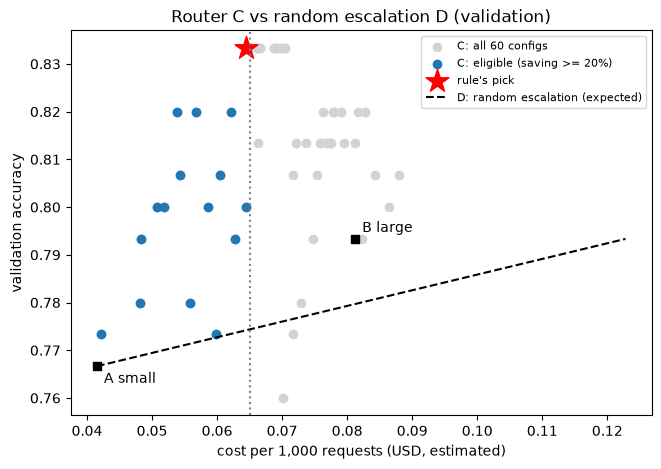

In [ ]:
import matplotlib.pyplot as plt

cA   = val.small_cost.mean() * 1000
aA   = val.small_ok.mean()
aB   = val.large_ok.mean()

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.scatter(sweep.cost_per_1k, sweep.acc, c="lightgray", label="C: all 60 configs")
el = sweep[sweep.saving >= MIN_SAVING]
ax.scatter(el.cost_per_1k, el.acc, c="tab:blue", label="C: eligible (saving >= 20%)")
ax.scatter(best.cost_per_1k, best.acc, marker="*", s=300, c="red", label="rule's pick")
ax.plot([cA, cA + cost_B], [aA, aB], "k--", label="D: random escalation (expected)")
ax.scatter([cA, cost_B], [aA, aB], c="black", marker="s")
ax.annotate("A small", (cA, aA), textcoords="offset points", xytext=(5, -12))
ax.annotate("B large", (cost_B, aB), textcoords="offset points", xytext=(5, 5))
ax.axvline(cost_B * (1 - MIN_SAVING), color="gray", ls=":")
ax.set_xlabel("cost per 1,000 requests (USD, estimated)")
ax.set_ylabel("validation accuracy")
ax.set_title("Router C vs random escalation D (validation)")
ax.legend(fontsize=8)
plt.show()

## FROZEN CONFIGURATION (chosen on validation only, before any test result for C or D)

Router C: escalate to the large model when the small model's output is invalid
OR the small model's label disagrees with S0's label.
t_v = 0 (verbalized-confidence signal off), t_s = 0 (S0-probability signal off),
use_disagree = True.

Picked by the pre-written rule (highest validation accuracy among configs with
cost saving >= 20% vs B). Validation: accuracy 0.833, escalation 38/150 (25.3%),
saving 20.7%. A tie with t_v=0.5 (identical escalations) went to the simpler config.

D: random escalation at the same count of escalated rows, 2000 draws, seed 0.
Test is computed once with exactly this configuration.

In [14]:
FROZEN = dict(t_v=0, t_s=0, use_disagree=True)

# the frozen config must be the rule's pick, otherwise stop
assert (best.t_v, best.t_s, bool(best.use_disagree)) == \
       (FROZEN["t_v"], FROZEN["t_s"], FROZEN["use_disagree"])

# validation only: on the rows the router keeps vs escalates, who is right?
val["esc"] = route(val, **FROZEN)
print(val.groupby("esc").agg(n=("gold", "size"),
                             small_right=("small_ok", "sum"),
                             large_right=("large_ok", "sum"),
                             s0_right=("s0_ok", "sum")))

         n  small_right  large_right  s0_right
esc                                           
False  112          105           99       105
True    38           10           20        13
